In [ ]:
from google.colab import drive
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn import svm
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

drive.mount('/content/drive')
file_path = '/content/drive/My Drive/Big Data & PA/Sleep_health_and_lifestyle_dataset.csv'
df = pd.read_csv(file_path, sep=';')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Data Exploration

In [ ]:
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration (Menit),Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,366,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,372,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,372,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,354,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,354,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration (Menit)   374 non-null    int64  
 5   Sleep Duration           374 non-null    float64
 6   Quality of Sleep         374 non-null    int64  
 7   Physical Activity Level  374 non-null    int64  
 8   Stress Level             374 non-null    int64  
 9   BMI Category             374 non-null    object 
 10  Blood Pressure           374 non-null    object 
 11  Heart Rate               374 non-null    int64  
 12  Daily Steps              374 non-null    int64  
 13  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(8), o

In [ ]:
df.describe()

,Person ID,Age,Sleep Duration (Menit),Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,427.925134,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,108.108742,8.673133,47.739404,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,1.000000,27.000000,348.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,94.250000,35.250000,384.000000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,187.500000,43.000000,432.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,280.750000,50.000000,468.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,374.000000,59.000000,510.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


In [ ]:
df.isnull().sum()

,0
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration (Menit),0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0


In [ ]:
rows = df[pd.isna(df["Sleep Disorder"])]
rows

,Person ID,Gender,Age,Occupation,Sleep Duration (Menit),Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,366,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,372,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,372,6.2,6,60,8,Normal,125/80,75,10000,NaN
7,8,Male,29,Doctor,468,7.8,7,75,6,Normal,120/80,70,8000,NaN
8,9,Male,29,Doctor,468,7.8,7,75,6,Normal,120/80,70,8000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
341,342,Female,56,Doctor,492,8.2,9,90,3,Normal Weight,118/75,65,10000,NaN
342,343,Female,56,Doctor,492,8.2,9,90,3,Normal Weight,118/75,65,10000,NaN
343,344,Female,57,Nurse,486,8.1,9,75,3,Overweight,140/95,68,7000,NaN
358,359,Female,59,Nurse,480,8.0,9,75,3,Overweight,140/95,68,7000,NaN


In [ ]:
df = df.fillna("None")
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration (Menit),Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,366,6.1,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,372,6.2,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,372,6.2,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,354,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,354,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [ ]:
df["BMI Category"] = df["BMI Category"].replace("Normal Weight", "Normal")

In [ ]:
df.drop('Person ID', axis=1, inplace=True)

In [ ]:
df[['Systolic BP', 'Diastolic BP']] = df['Blood Pressure'].str.split('/', expand=True)
df[['Systolic BP', 'Diastolic BP']] = df[['Systolic BP', 'Diastolic BP']].apply(pd.to_numeric)
df = df.drop('Blood Pressure', axis=1)

In [ ]:
df.head()

,Gender,Age,Occupation,Sleep Duration (Menit),Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic BP,Diastolic BP
0,Male,27,Software Engineer,366,6.1,6,42,6,Overweight,77,4200,None,126,83
1,Male,28,Doctor,372,6.2,6,60,8,Normal,75,10000,None,125,80
2,Male,28,Doctor,372,6.2,6,60,8,Normal,75,10000,None,125,80
3,Male,28,Sales Representative,354,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
4,Male,28,Sales Representative,354,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90


In [ ]:
dict = {}
for i in list(df.columns):
    dict[i] = df[i].value_counts().shape[0]
pd.DataFrame(dict, index=["unique count"]).transpose()

,unique count
Gender,2
Age,31
Occupation,11
Sleep Duration (Menit),27
Sleep Duration,27
Quality of Sleep,6
Physical Activity Level,16
Stress Level,6
BMI Category,3
Heart Rate,19


In [ ]:
for col in df.columns:
  unique_values = df[col].unique()
  print(f"Unique values for column '{col}': {unique_values}")

Unique values for column 'Gender': ['Male' 'Female']
Unique values for column 'Age': [27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 48 49 50 51 52
 53 54 55 56 57 58 59]
Unique values for column 'Occupation': ['Software Engineer' 'Doctor' 'Sales Representative' 'Teacher' 'Nurse'
 'Engineer' 'Accountant' 'Scientist' 'Lawyer' 'Salesperson' 'Manager']
Unique values for column 'Sleep Duration (Menit)': [366 372 354 378 468 360 390 456 462 474 384 450 432 348 402 438 444 426
 396 414 480 408 486 498 510 504 492]
Unique values for column 'Sleep Duration': [6.1 6.2 5.9 6.3 7.8 6.  6.5 7.6 7.7 7.9 6.4 7.5 7.2 5.8 6.7 7.3 7.4 7.1
 6.6 6.9 8.  6.8 8.1 8.3 8.5 8.4 8.2]
Unique values for column 'Quality of Sleep': [6 4 7 5 8 9]
Unique values for column 'Physical Activity Level': [42 60 30 40 75 35 45 50 32 70 80 55 90 47 65 85]
Unique values for column 'Stress Level': [6 8 7 4 3 5]
Unique values for column 'BMI Category': ['Overweight' 'Normal' 'Obese']
Unique values for column 'Heart R

In [ ]:
for col in df.columns:
  unique_values = df[col].unique()
  for value in unique_values:
    count = df[col].value_counts()[value]
    print(f"Column: '{col}', Value: '{value}', Count: {count}")

Column: 'Gender', Value: 'Male', Count: 189
Column: 'Gender', Value: 'Female', Count: 185
Column: 'Age', Value: '27', Count: 1
Column: 'Age', Value: '28', Count: 5
Column: 'Age', Value: '29', Count: 13
Column: 'Age', Value: '30', Count: 13
Column: 'Age', Value: '31', Count: 18
Column: 'Age', Value: '32', Count: 17
Column: 'Age', Value: '33', Count: 13
Column: 'Age', Value: '34', Count: 2
Column: 'Age', Value: '35', Count: 12
Column: 'Age', Value: '36', Count: 12
Column: 'Age', Value: '37', Count: 20
Column: 'Age', Value: '38', Count: 20
Column: 'Age', Value: '39', Count: 15
Column: 'Age', Value: '40', Count: 4
Column: 'Age', Value: '41', Count: 12
Column: 'Age', Value: '42', Count: 9
Column: 'Age', Value: '43', Count: 34
Column: 'Age', Value: '44', Count: 30
Column: 'Age', Value: '45', Count: 14
Column: 'Age', Value: '48', Count: 3
Column: 'Age', Value: '49', Count: 11
Column: 'Age', Value: '50', Count: 20
Column: 'Age', Value: '51', Count: 8
Column: 'Age', Value: '52', Count: 9
Column

In [ ]:
sleep_order_index = df.columns.get_loc('Sleep Disorder')
columns = list(df.columns[:sleep_order_index]) + list(df.columns[sleep_order_index+1:]) + ['Sleep Disorder']
df = df[columns]
df.head()

,Gender,Age,Occupation,Sleep Duration (Menit),Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Systolic BP,Diastolic BP,Sleep Disorder
0,Male,27,Software Engineer,366,6.1,6,42,6,Overweight,77,4200,126,83,None
1,Male,28,Doctor,372,6.2,6,60,8,Normal,75,10000,125,80,None
2,Male,28,Doctor,372,6.2,6,60,8,Normal,75,10000,125,80,None
3,Male,28,Sales Representative,354,5.9,4,30,8,Obese,85,3000,140,90,Sleep Apnea
4,Male,28,Sales Representative,354,5.9,4,30,8,Obese,85,3000,140,90,Sleep Apnea


# Data Visualization


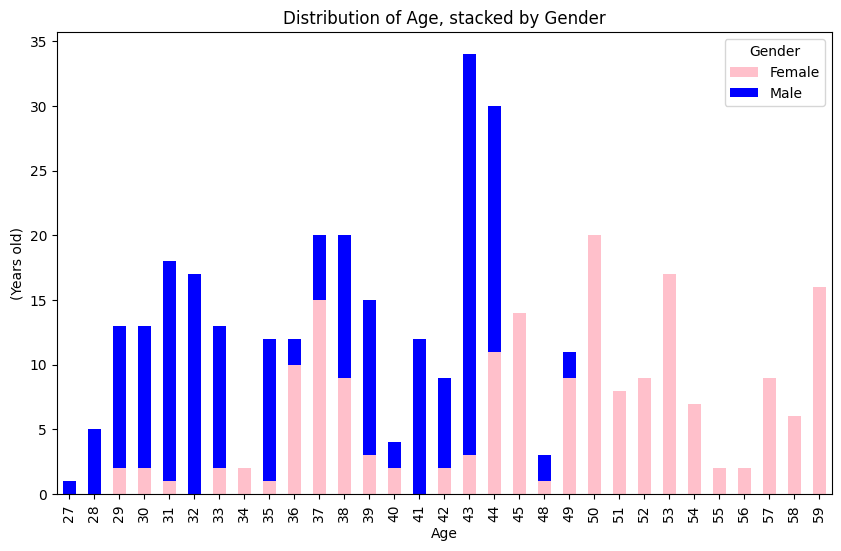

In [ ]:
df_gender = df.groupby(['Age', 'Gender']).size().unstack().fillna(0)
colors = ['pink', 'blue']
ax = df_gender.plot(kind='bar', stacked=True, color=colors, figsize=(10, 6))
plt.xlabel('Age')
plt.ylabel('(Years old)')
plt.title('Distribution of Age, stacked by Gender')
plt.legend(title='Gender', labels=['Female', 'Male'])
plt.show()

Text(0.5, 1.0, 'Distribution of Sleep Duration')

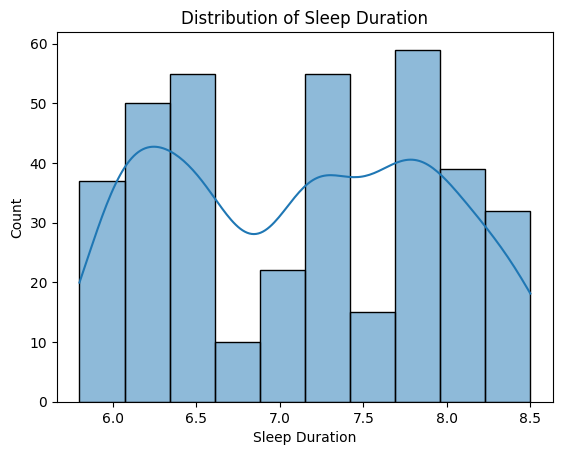

In [ ]:
ax = sns.histplot(data=df, x="Sleep Duration", kde=True)
plt.title('Distribution of Sleep Duration')

<Axes: title={'center': 'Distribution of Sleep Disorder '}, ylabel='proportion'>

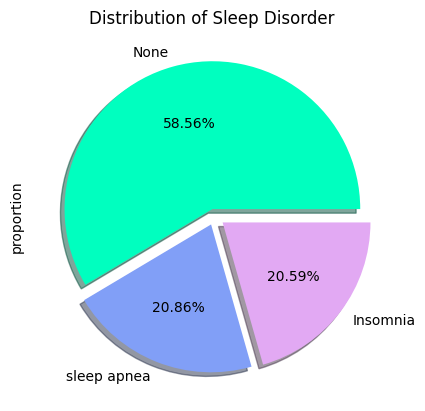

In [ ]:
df['Sleep Disorder'].value_counts(normalize=True).sort_values(ascending=False).plot(
    kind='pie', title='Distribution of Sleep Disorder ', explode=[0.05, 0.06, 0.07],
    labels=['None', 'sleep apnea', 'Insomnia'], colors=['#00FFBF', '#819FF7', '#E2A9F3'],
    autopct='%1.2f%%', shadow=True
)

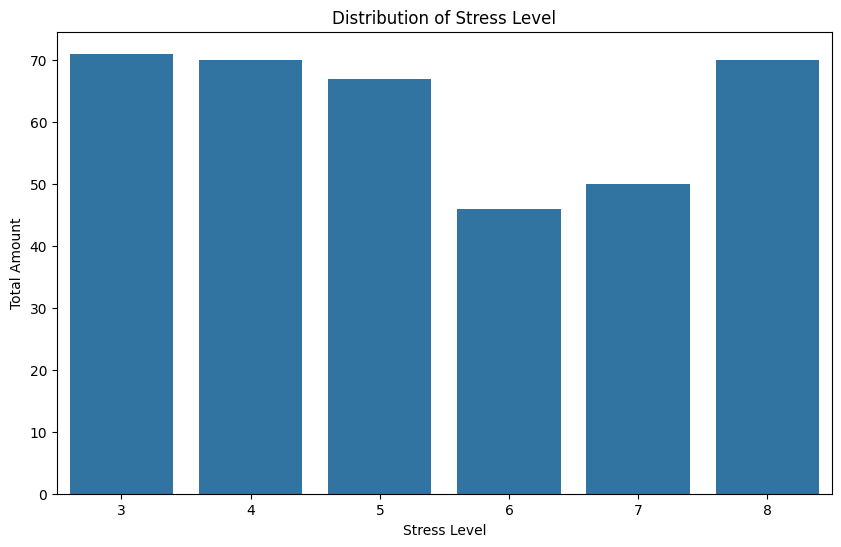

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(x='Stress Level', data=df)
plt.xlabel('Stress Level')
plt.ylabel('Total Amount')
plt.title('Distribution of Stress Level')
plt.show()

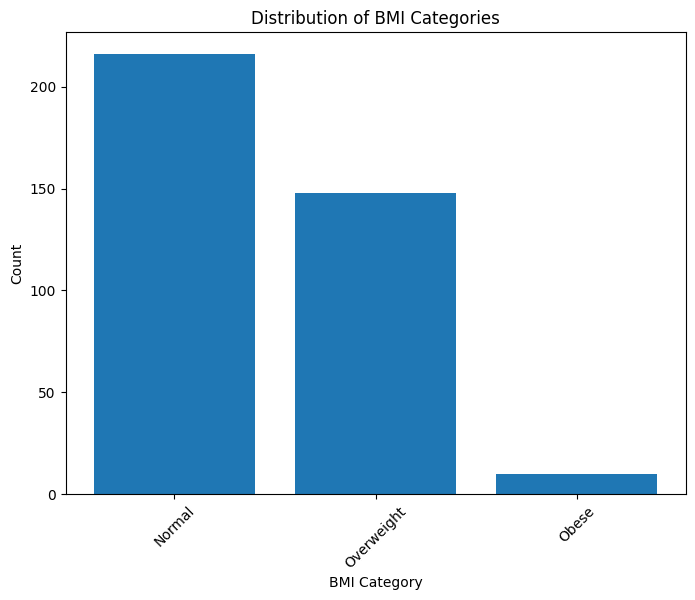

In [ ]:
bmi_counts = df['BMI Category'].value_counts()
plt.figure(figsize=(8, 6))
plt.bar(bmi_counts.index, bmi_counts.values)
plt.title("Distribution of BMI Categories")
plt.xlabel("BMI Category")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

# Data Processing

In [ ]:
label_encoder = LabelEncoder()
cat_cols = ['Gender', 'Occupation', 'BMI Category', 'Sleep Disorder']
for col in cat_cols:
    df[col] = label_encoder.fit_transform(df[col])
df.head(20)

,Gender,Age,Occupation,Sleep Duration (Menit),Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Systolic BP,Diastolic BP,Sleep Disorder
0,1,27,9,366,6.1,6,42,6,2,77,4200,126,83,1
1,1,28,1,372,6.2,6,60,8,0,75,10000,125,80,1
2,1,28,1,372,6.2,6,60,8,0,75,10000,125,80,1
3,1,28,6,354,5.9,4,30,8,1,85,3000,140,90,2
4,1,28,6,354,5.9,4,30,8,1,85,3000,140,90,2
5,1,28,9,354,5.9,4,30,8,1,85,3000,140,90,0
6,1,29,10,378,6.3,6,40,7,1,82,3500,140,90,0
7,1,29,1,468,7.8,7,75,6,0,70,8000,120,80,1
8,1,29,1,468,7.8,7,75,6,0,70,8000,120,80,1
9,1,29,1,468,7.8,7,75,6,0,70,8000,120,80,1


In [ ]:
corr_matrix = df.corr()
print(corr_matrix)

                           Gender       Age  Occupation  \
Gender                   1.000000 -0.596358   -0.219113   
Age                     -0.596358  1.000000    0.231188   
Occupation              -0.219113  0.231188    1.000000   
Sleep Duration (Menit)  -0.121579  0.344709   -0.325775   
Sleep Duration          -0.121579  0.344709   -0.325775   
Quality of Sleep        -0.291366  0.473734   -0.278071   
Physical Activity Level  0.001454  0.178993   -0.103660   
Stress Level             0.396018 -0.422344    0.021123   
BMI Category            -0.339945  0.523881    0.694390   
Heart Rate               0.217105 -0.225606    0.043928   
Daily Steps             -0.014509  0.057973   -0.105877   
Systolic BP             -0.210527  0.605878    0.518561   
Diastolic BP            -0.268378  0.593839    0.521835   
Sleep Disorder          -0.253415  0.232000   -0.169800   

                         Sleep Duration (Menit)  Sleep Duration  \
Gender                                -0.121579

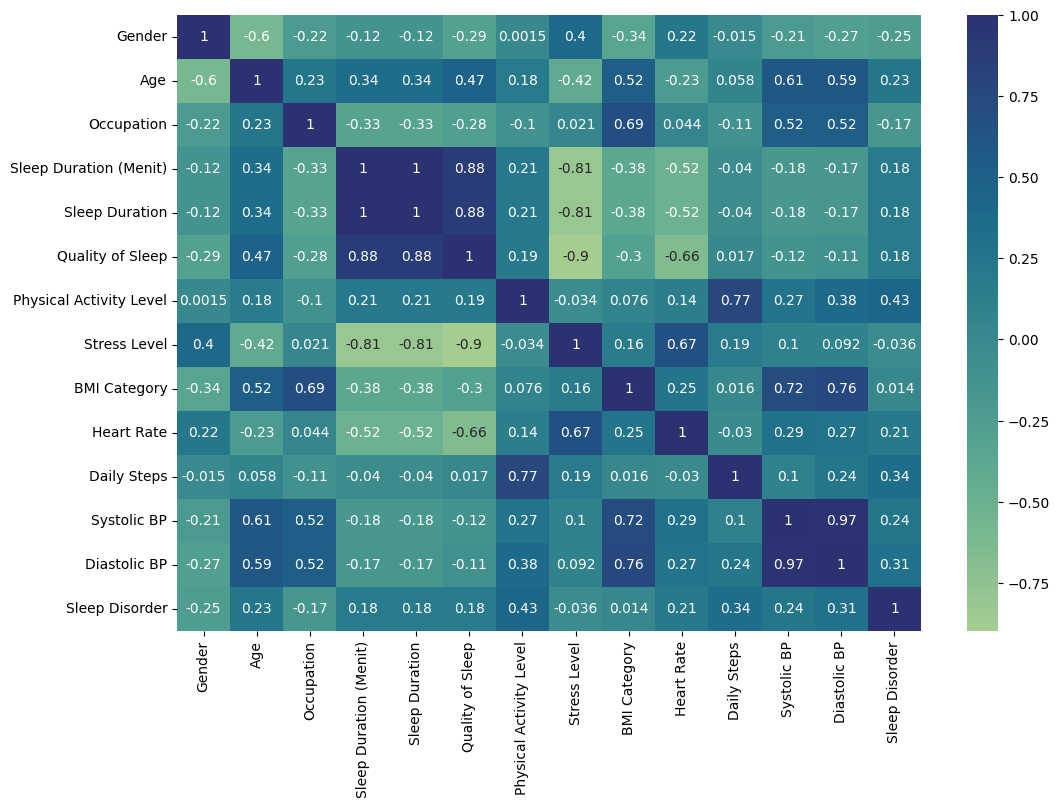

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), cmap='crest', annot=True)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X = df.drop(['Sleep Disorder'], axis=1)
y = df['Sleep Disorder']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (299, 13)
y_train shape: (299,)
X_test shape: (75, 13)
y_test shape: (75,)


Multiple Linear Regression

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


The test accuracy of Logistic Regression is : 85.33%

Classification Report:
              precision    recall  f1-score   support

        None       0.74      0.88      0.80        16
 Sleep Apnea       0.89      0.93      0.91        43
    Insomnia       0.91      0.62      0.74        16

    accuracy                           0.85        75
   macro avg       0.84      0.81      0.82        75
weighted avg       0.86      0.85      0.85        75



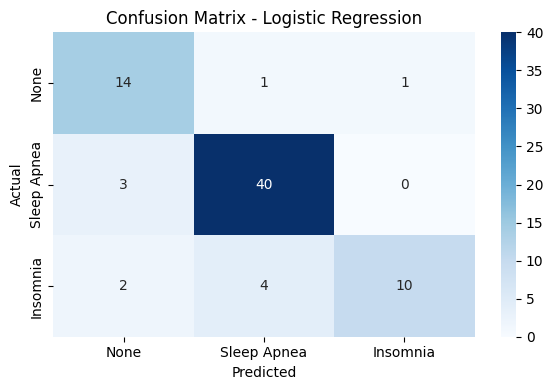

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
accuracy = accuracy_score(y_test, lr_pred)
print(f"The test accuracy of Logistic Regression is : {accuracy * 100:.2f}%")
print("\nClassification Report:")
class_names = ['None', 'Sleep Apnea', 'Insomnia']
print(classification_report(y_test, lr_pred, target_names=class_names))
cm = confusion_matrix(y_test, lr_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Logistic Regression')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

Teorema Bayes / Naive Bayes

The test accuracy of Naive Bayes is : 86.67%

Classification Report:
              precision    recall  f1-score   support

        None       0.68      0.81      0.74        16
 Sleep Apnea       0.95      0.93      0.94        43
    Insomnia       0.86      0.75      0.80        16

    accuracy                           0.87        75
   macro avg       0.83      0.83      0.83        75
weighted avg       0.87      0.87      0.87        75



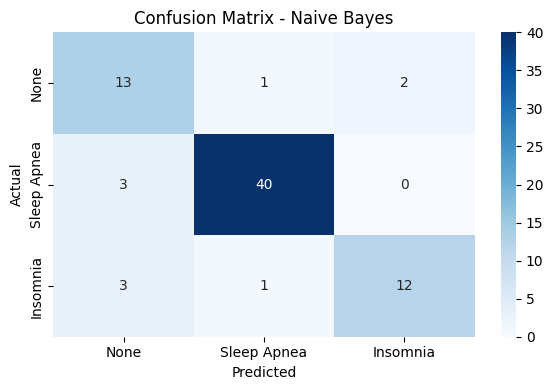

In [ ]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)
nb_pred = nb.predict(X_test)
accuracy = accuracy_score(y_test, nb_pred)
print(f"The test accuracy of Naive Bayes is : {accuracy * 100:.2f}%")
print("\nClassification Report:")
class_names = ['None', 'Sleep Apnea', 'Insomnia']
print(classification_report(y_test, nb_pred, target_names=class_names))
cm = confusion_matrix(y_test, nb_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Naive Bayes')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

KKN classifier

The test accuracy of KNN is : 85.33%

Classification Report:
              precision    recall  f1-score   support

        None       0.67      0.88      0.76        16
 Sleep Apnea       0.95      0.93      0.94        43
    Insomnia       0.83      0.62      0.71        16

    accuracy                           0.85        75
   macro avg       0.82      0.81      0.80        75
weighted avg       0.87      0.85      0.85        75



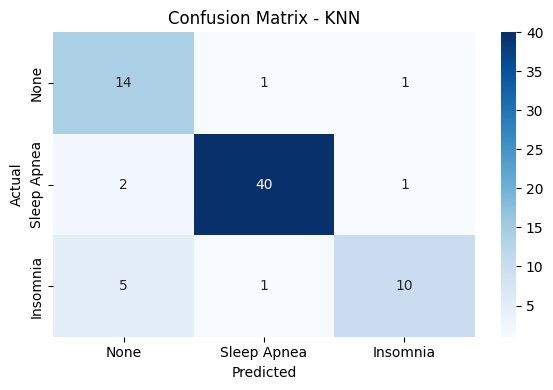

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

kkn = KNeighborsClassifier()
kkn.fit(X_train, y_train)
kkn_pred = kkn.predict(X_test)

accuracy = accuracy_score(y_test, kkn_pred)
print(f"The test accuracy of KNN is : {accuracy * 100:.2f}%")
print("\nClassification Report:")

class_names = ['None', 'Sleep Apnea', 'Insomnia']
print(classification_report(y_test, kkn_pred, target_names=class_names))

cm = confusion_matrix(y_test, kkn_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - KNN')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

Random Forest Classifier

The test accuracy of Random Forest Classifier is : 88.00%

Classification Report:
              precision    recall  f1-score   support

        None       0.72      0.81      0.76        16
 Sleep Apnea       0.95      0.98      0.97        43
    Insomnia       0.85      0.69      0.76        16

    accuracy                           0.88        75
   macro avg       0.84      0.83      0.83        75
weighted avg       0.88      0.88      0.88        75



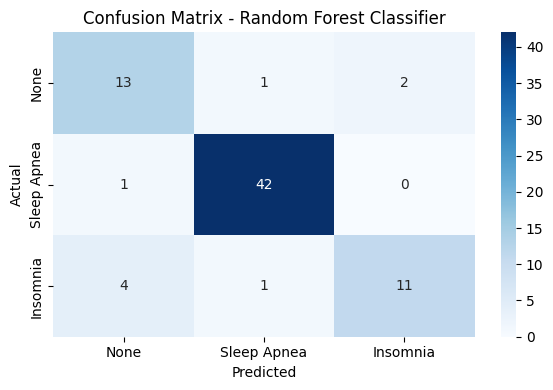

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=13)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
accuracy = accuracy_score(y_test, rf_pred)
print(f"The test accuracy of Random Forest Classifier is : {accuracy * 100:.2f}%")
print("\nClassification Report:")
class_names = ['None', 'Sleep Apnea', 'Insomnia']
print(classification_report(y_test, rf_pred, target_names=class_names))
cm = confusion_matrix(y_test, rf_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Random Forest Classifier')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

Decision Tree

The test accuracy of Decision Tree is : 89.33%

Classification Report:
              precision    recall  f1-score   support

        None       0.76      0.81      0.79        16
 Sleep Apnea       0.95      0.98      0.97        43
    Insomnia       0.86      0.75      0.80        16

    accuracy                           0.89        75
   macro avg       0.86      0.85      0.85        75
weighted avg       0.89      0.89      0.89        75



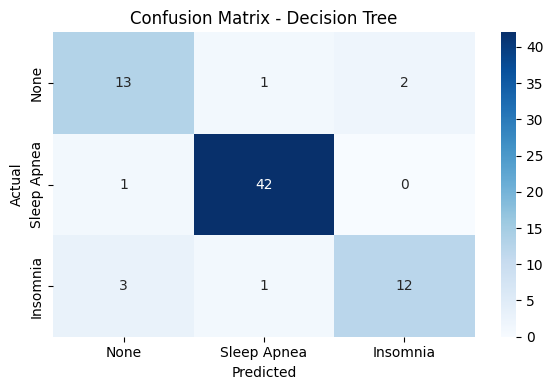

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
accuracy = accuracy_score(y_test, dt_pred)
print(f"The test accuracy of Decision Tree is : {accuracy * 100:.2f}%")
print("\nClassification Report:")
class_names = ['None', 'Sleep Apnea', 'Insomnia']
print(classification_report(y_test, dt_pred, target_names=class_names))
cm = confusion_matrix(y_test, dt_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Decision Tree')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

/tmp/ipykernel_28240/2999824341.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Accuracy', y='Model', data=df_accuracy, palette='viridis')


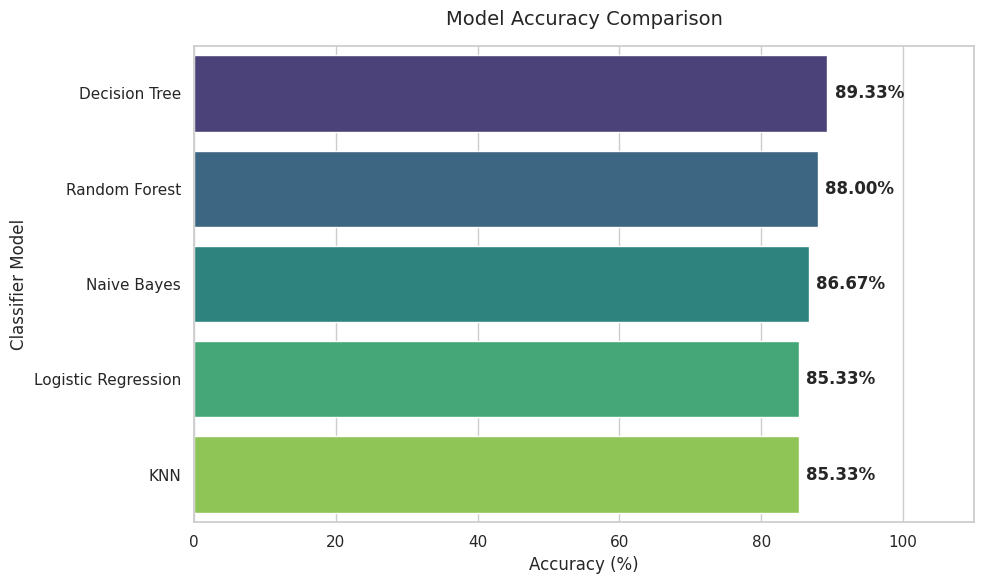

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import accuracy_score
accuracies = {
    'Logistic Regression': accuracy_score(y_test, lr_pred) * 100,
    'Naive Bayes': accuracy_score(y_test, nb_pred) * 100,
    'KNN': accuracy_score(y_test, kkn_pred) * 100,
    'Random Forest': accuracy_score(y_test, rf_pred) * 100,
    'Decision Tree': accuracy_score(y_test, dt_pred) * 100
}
df_accuracy = pd.DataFrame(list(accuracies.items()), columns=['Model', 'Accuracy'])
df_accuracy = df_accuracy.sort_values(by='Accuracy', ascending=False)
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x='Accuracy', y='Model', data=df_accuracy, palette='viridis')
for index, value in enumerate(df_accuracy['Accuracy']):
    ax.text(value + 1, index, f'{value:.2f}%', va='center', fontweight='bold')

plt.title('Model Accuracy Comparison', fontsize=14, pad=15)
plt.xlabel('Accuracy (%)', fontsize=12)
plt.ylabel('Classifier Model', fontsize=12)
plt.xlim(0, 110)
plt.tight_layout()
plt.show()